In [1]:
from data_extractor import data_analysis
from Energy import 
Data_collect = data_analysis("./ff0.15_np1_10ms",10,1)

Iniciando análisis de 1001 archivos...
Iniciando análisis de datos
100/100%|####################|

In [2]:
import gzip

# Ajustá esto a tu archivo real
ruta_archivo = f"ff0.15_np1_10ms/output.42000.gz" 

print(f"Investigando: {ruta_archivo}...")

with gzip.open(ruta_archivo, 'rt') as f: # 'rt' para leer texto y ver qué pasa
    
    # 1. Saltamos las 9 filas basura
    for _ in range(8):
        next(f)
        
    # 2. Leemos la cabecera (fila 10) para establecer la "ley"
    # OJO: Acá simulo lo que hace Polars con separator=" "
    linea_header = next(f).strip()
    columnas_esperadas = len(linea_header.split(" ")) # Split por espacio simple
    
    print(f"Header detectado: {linea_header}")
    print(f"Esperando {columnas_esperadas} columnas por separación de espacio simple.")
    print("-" * 30)

    # 3. Buscamos al criminal
    for i, linea in enumerate(f):
        linea_limpia = linea.strip()
        
        # Simulamos el split por espacio que hace Polars
        columnas_actuales = len(linea_limpia.split(" "))
        
        if columnas_actuales != columnas_esperadas:
            print(f"¡CULPABLE ENCONTRADO EN LA FILA DE DATOS {i+1} (Fila real {i+11})!")
            print(f"Columnas encontradas: {columnas_actuales}")
            print(f"Columnas esperadas:   {columnas_esperadas}")
            print("\n--- CONTENIDO DE LA LÍNEA ---")
            print(f"'{linea_limpia}'") # Las comillas te ayudan a ver espacios al final
            print("-----------------------------")
            
            # Frenamos acá para que analices
            break
            
    else:
        print("El script recorrió todo y no encontró inconsistencias con split(' ').")
        print("El problema podría ser caracteres invisibles o tipos de datos.")

Investigando: ff0.15_np1_10ms/output.42000.gz...
Header detectado: 43337 1 3.60244994356e-05 6.7889557514e-07 1.10350263413e-07 9.11241960675e-05 -2.68116402281e-05 4.41897852133e-05 10.8418901417 50.7556905712 66.4133426191
Esperando 11 columnas por separación de espacio simple.
------------------------------
¡CULPABLE ENCONTRADO EN LA FILA DE DATOS 81035 (Fila real 81045)!
Columnas encontradas: 16
Columnas esperadas:   11

--- CONTENIDO DE LA LÍNEA ---
'81576 2 5e-05 5e-05 9.66350000002e-05  0  0 -10  0  0  0'
-----------------------------


Delta K de la cama entre el principio y el final de la simulación
   -Disminuyó: -99.79 %


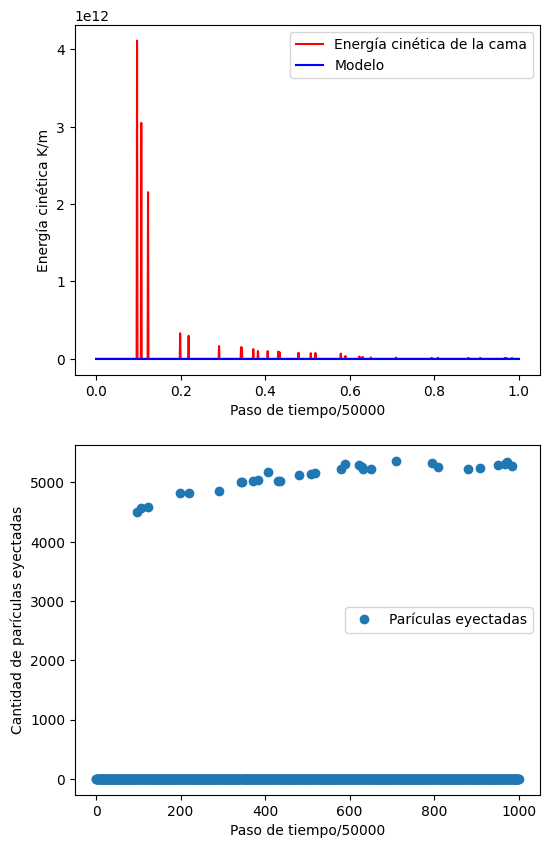

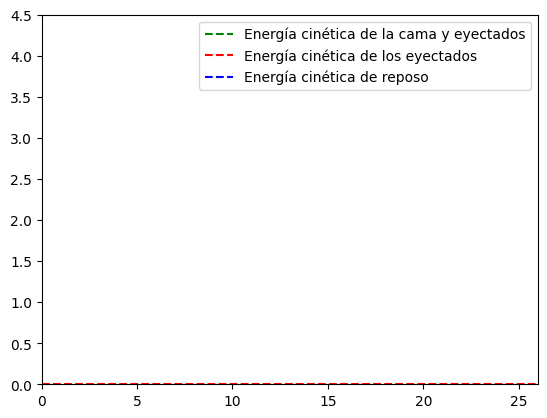

In [2]:
import matplotlib.pyplot as plt 
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import t
## Definimos el modelo que queremos ajustar
def modelo(x,a,b,c,d):
    return a*(x-d)*np.exp(-b*x)+c
## Le sacamos las derivadas aprciales respecto  a los parámetros que le queremos ajustar
def derA(x,a,b,c,d):
    return (x-d)*np.exp(-b*x)
def derB(x,a,b,c,d):
    return -a*(x-d)*x*np.exp(-b*x)
def derC(x,a,b,c,d):
    return 1
def derD(x,a,b,c,d):
    return a*(b*x-1)*np.exp(-b*x)
## Definimos el gradiente 
def grad(x,popt):
    return np.array([derA(x,*popt),derB(x,*popt),derC(x,*popt),derD(x,*popt)])
## Buscamos la desviación estandar del ajuste usando la matriz de covarianza
def errorf(absisa,popt,pcov):
    return np.array([np.sqrt(grad(x,popt).T @ pcov @ grad(x,popt)) if x!=0 else 0 for x in absisa])
## Energía de las partículas de la cama menos el proyectil a t=0

K_cama = np.array(Data_collect["K"])
K_eyectados = np.array(Data_collect['Eyectados_K'])
K = K_cama-K_eyectados
## Hacemos el ajuste
popt, pcov = curve_fit(modelo,np.linspace(0,1000,num=1001)/1000,K)

## Velocidad del CM a tiempo t
Vcm = np.array(Data_collect['Vcm'])
Vcm2 = np.linalg.norm(Vcm,axis=1)
## Para hacer el plot continuo
X = np.linspace(0,(len(K_cama)-1)/1000,500)
t_student = t.ppf(0.975,len(K_cama))

#########################################
# Plots #################################
#########################################
print(f"Delta K de la cama entre el principio y el final de la simulación\n   -{"Aumentó:" if (K[-1]-K[0])>0 else "Disminuyó:"} {(K[-1]-K[0])/K[0]*100:.2f} %")
fig,ax = plt.subplots(2,1,figsize=(6,10))
# En este plot tiene la energía cinética de la cama, con ajuste 
ax[0].plot(np.linspace(0,1000,num=1001)/1000,K,"r-",label="Energía cinética de la cama")
ax[0].plot(X,modelo(X,*popt),"b-",label="Modelo")
#ax[0].fill_between(X,modelo(X,*popt)-errorf(X,popt,pcov)*t_student,modelo(X,*popt)+errorf(X,popt,pcov)*t_student,alpha=0.5,label=r"error del ajuste")
#ax[0].plot(Vcm2/max(Vcm2),"o",label="Módulo del momento del sistema\nnormalizado",markersize=1)
ax[0].legend()
ax[0].set_xlabel("Paso de tiempo/50000")
ax[0].set_ylabel("Energía cinética K/m")

ax[1].plot(Data_collect['Eyección'],"o",label="Parículas eyectadas")
ax[1].set_xlabel("Paso de tiempo/50000")
ax[1].set_ylabel("Cantidad de parículas eyectadas")
ax[1].legend()
plt.show()

plt.plot(K_cama,"g--",label="Energía cinética de la cama y eyectados")
plt.plot(K_eyectados,"r--",label="Energía cinética de los eyectados")
plt.plot(K,"b--",label="Energía cinética de reposo")
#plt.fill_between(np.linspace(0,1000,1001),np.array(Data_collect["Min"])*0.5,np.array(Data_collect["Max"])*0.5,alpha=0.5,label=r"Máx y min de la cama")

plt.xlim((0,26))
plt.ylim((0,4.5))
plt.legend()



In [ ]:
#%matplotlib qt   ## Hacer el grafico interactivo
%matplotlib inline

fig = plt.figure()
ax = fig.add_subplot(111,projection="3d")
ax.plot(vx,vy,zs=vz)

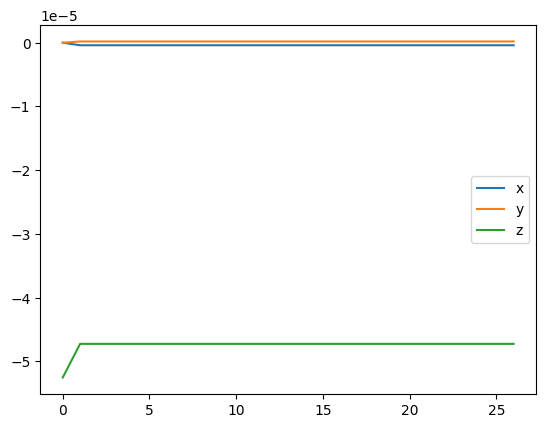

In [34]:
plt.plot(Vcm[:,0],label="x")
plt.plot(Vcm[:,1],label="y")
plt.plot(Vcm[:,2],label="z")
plt.legend()

In [1]:

def escrituraparquet(ruta):
    """La funcion escritura sirve para transformar archivos gz en parquet

    Args:
        ruta (str): Es la ruta donde se encuentran los archivos csv
    """

    ## Definimos la carpeta donde estan los outputs de la sim.
    Archivos = [archivo for archivo in listdir(ruta) if (archivo.startswith("output.") and ".gz" in archivo)]
    print("Iniciando conversión de archivos gz a parquet")
    print("000/100%|",20*"-","|",sep="",end="")
    for i,archivo in enumerate(Archivos,1):
        nombre = archivo.replace(".gz","")
        if  not path.isfile(f"{ruta}/datos/{nombre}.parquet"): ## Ver si no lo convertimos antes
            print("\r","{:03d}".format(int(i*100/len(Archivos)//1)),"/100%|",int((i*100/len(Archivos))//5)*"#",sep="",end="")
            ## Escirbir archivo ....
            with opengz(f'{ruta}/{nombre}.gz', 'rb') as csv_file:
                df_pd = pd.read_csv(
            csv_file,
	    sep = '\s+',
            skiprows=9,
            names=["id","type","x","y","z","vx","vy","vz","omegax","omegay","omegaz","c_1"])
        # 2. ESCRITURA EFICIENTE (Directo a Parquet)
        # Pandas usa PyArrow por debajo, es muy eficiente para escribir
                df_pd.to_parquet(f"{ruta}/datos/{nombre}.parquet", compression='snappy', index=False)
    print("conversión exitosa")

def checkparquet(ruta)->int:
    """Esta funcion cuenta la cantidad de archivos que se transformaron en parquet
    Args:
        ruta (str): es la ruta donde se encuentran los archivos output.
    Returns:
        int: Cantidad de carpetas que hay en el directorio de la simulación
        Paso (int): Cantidad de pasos que salta entre archivos
    """
    if not path.isdir(f"{ruta}/datos"): mkdir(f"{ruta}/datos")
    carpetas = [d for d in listdir(f"{ruta}/datos") if d.startswith("output.") and not ".gz" in d]
    if not carpetas:
        print("No hay datos registrados todavía.")
        return 0,0
    paso = sorted([float(i.replace("output.","").replace(".parquet", "")) for i in carpetas]) ## El primer elemnto es el 0, el segundo es el paso
    return len(carpetas), paso[1]


In [29]:
import pandas as pd
def lecturaparquet(i, paso, movimiento, angulo, vel):
    ruta = "erosion_bed_SI_ff_0.35_np_1_vel_-10_angle_0_move_0_0_0"
    return pd.read_parquet(f"{ruta}/datos/output.{i*paso}.parquet",  columns=["id","type","x","y","z","vx","vy","vz","c_1"])

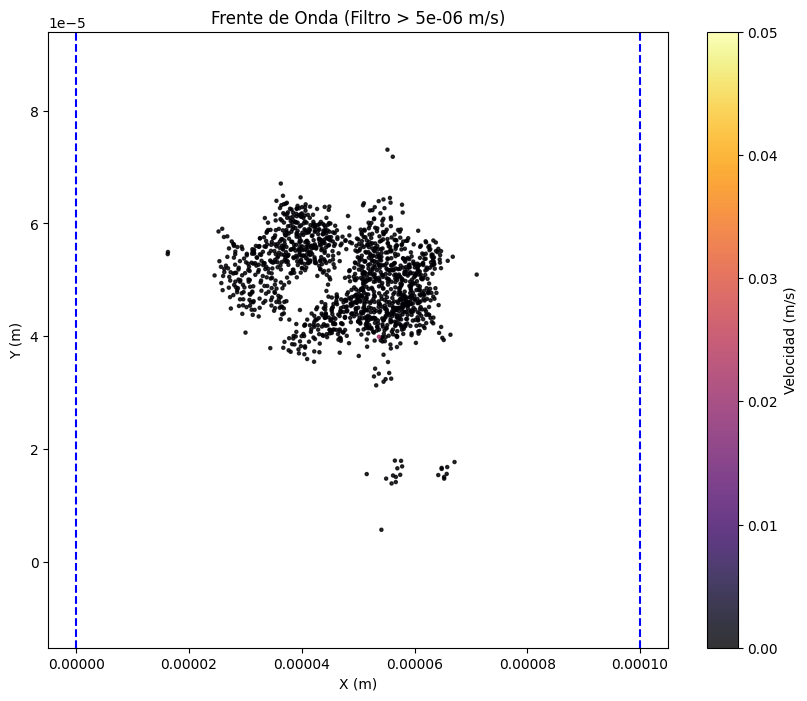

In [40]:
import numexpr as ne
import matplotlib.pyplot as plt
def graficar_onda(i, paso, movimiento, angulo, vel):
    """
    graficar_onda es una funcion que plotea un scatter en el plano xy donde mediante un mapa de colores se muestra la
    magnitud cuadrada de la velocidad evolucionando en el tiempo
    Args:
        i (int): es el paso de simulacion de deonde se van a  sacar los datos
    """
    df = lecturaparquet(i, paso, movimiento, angulo, vel)
    
    # Filtramos la cama
    df = df[df["type"] == 1]
    
    # Calculamos velocidad magnitud
    vx = df["vx"].to_numpy()
    vy = df["vy"].to_numpy()
    vz = df["vz"].to_numpy()
    x  = df["x"].to_numpy()
    y  = df["y"].to_numpy()
    v_mag = ne.evaluate("vx**2 + vy**2 + vz**2")
    
    # Filtramos el ruido de fondo
    # Solo mostramos partículas que se muevan más rápido que el 10% de tu vmax actual
    # Como tu vmax es 0.05, el umbral será 0.005 m/s
    umbral_visual = 0.000005 
    mask_activos = v_mag > umbral_visual
    
    plt.figure(figsize=(10, 8))
    
    # Graficamos SOLO las partículas activas
    # Aumenté 's' un poco para que los puntos se vean mejor
    plt.scatter(x[mask_activos], y[mask_activos], 
                c=v_mag[mask_activos], 
                cmap="inferno",  # 'inferno' o 'magma' suelen verse mejor que 'hot' sobre fondo blanco
                s=5,             # Puntos un poco más grandes
                alpha=0.8, 
                vmin=0, vmax=0.05)
    
    plt.colorbar(label="Velocidad (m/s)")
    plt.title(f"Frente de Onda (Filtro > {umbral_visual} m/s)")
    plt.xlabel("X (m)")
    plt.ylabel("Y (m)")
    
    # Bordes
    plt.axvline(x=0.00010, color='blue', linestyle='--')
    plt.axvline(x=0.00000, color='blue', linestyle='--')
    
    plt.axis('equal') # Importante para no distorsionar la forma circular
    plt.show()
# Usalo con el último archivo de una simulación
graficar_onda(26,paso=50000,movimiento=[0,0,0],angulo=0,vel=-10)

Generando video de 26 cuadros...


IndexError: list index out of range

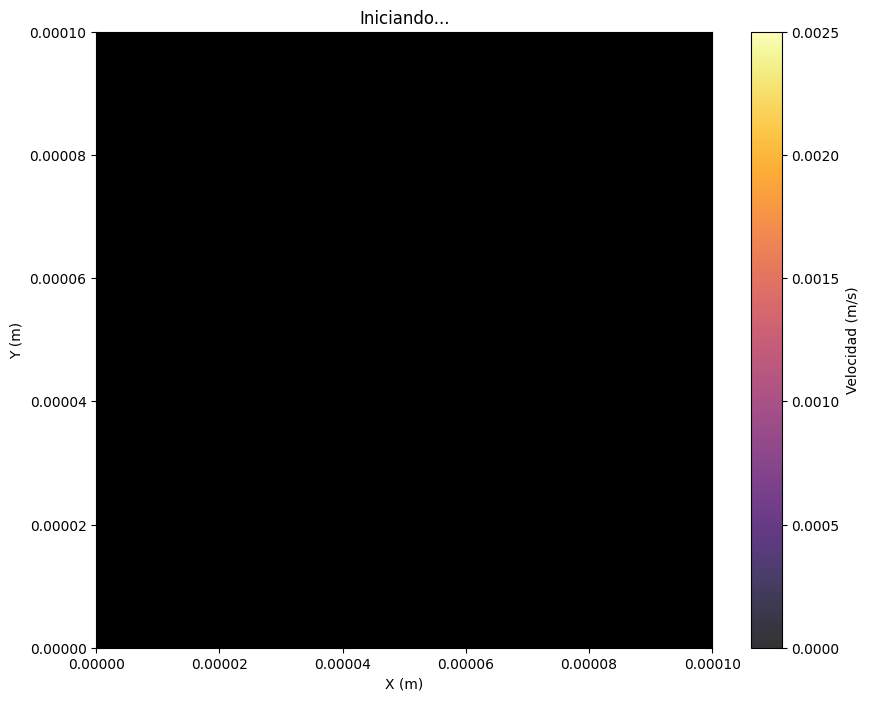

In [10]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import pandas as pd
import numpy as np
import numexpr as ne


# --- CONFIGURACIÓN DE TU SIMULACIÓN ---
# Ajusta estos valores a los de tu simulación real
MOVIMIENTO = [0, 0, 0]
ANGULO = 0
VEL = -10
PASO = 50000  # El salto entre archivos (output.0, output.50000, etc.)
FF = 0.35
NP_PART = 1

# Configuración del video
NOMBRE_VIDEO = "animacion_tesis.mp4"
FRAMES_TOTALES = 26
FPS = 5
# Configuración Visual
VMAX = 0.05**2
UMBRAL_VISUAL = 0.005**2


# --- PREPARACIÓN DE LA FIGURA ---
fig, ax = plt.subplots(figsize=(10, 8))

# Ajusta estos límites al tamaño real de tu caja de simulación
ax.set_xlim(0, 0.0001) 
ax.set_ylim(0, 0.0001)
ax.set_aspect('equal')
ax.set_facecolor('black')

titulo = ax.set_title("Iniciando...")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")

# Scatter plot inicial vacío
scatter = ax.scatter([], [], c=[], s=5, cmap="inferno", vmin=0, vmax=VMAX, alpha=0.8)
fig.colorbar(scatter, ax=ax, label="Velocidad (m/s)")

def init():
    """Limpia el gráfico antes de empezar."""
    scatter.set_offsets(np.empty((0, 2)))
    return scatter, titulo

def update(i):
    """
    Función que llama a TU lecturaparquet para cada cuadro 'i'.
    """

    # Llamamos a tu función con los parámetros globales
    df = lecturaparquet(i, PASO, MOVIMIENTO, ANGULO, VEL, FF, NP_PART)
    
    if df is None:
        return scatter, titulo

    # --- FILTRO VISUAL ---
    # Calculamos magnitud de velocidad
    vx = df["vx"].to_numpy()
    vy = df["vy"].to_numpy().to_numpy()
    vz = df["vz"].to_numpy()
    x  = df["x"].to_numpy()
    y  = df["y"].to_numpy()
    v_mag = ne.evaluate("vx**2 + vy**2 + vz**2")
    
    # Filtramos la cama (type 1) y eliminamos partículas quietas (ruido)
    mask =  (v_mag > UMBRAL_VISUAL)
    
    if np.any(mask):
        # Datos para graficar (X, Y)
        data_xy = np.column_stack((x[mask], y[mask]))
        colores = v_mag[mask]
        
        scatter.set_offsets(data_xy)
        scatter.set_array(colores)
        
        # Actualizamos el título con el paso actual
        titulo.set_text(f"Paso: {i * PASO}")
    else:
        scatter.set_offsets(np.empty((0, 2)))
        
    return scatter, titulo

# --- GENERAR ANIMACIÓN ---
print(f"Generando video de {FRAMES_TOTALES} cuadros...")

ani = animation.FuncAnimation(fig, update, frames=range(FRAMES_TOTALES), 
                              init_func=init, blit=False, interval=50)

ani.save("animacion_tesis.gif", writer='pillow', fps=FPS)
print(" GIF guardado.")

plt.close()

In [ ]:
from matplotlib.animation import FuncAnimation
import matplotlib.pyplot as plt
import numpy as np
import numexpr as ne

def update_soliton(i):
    """
    update_soliton
    - Modulo cuadrado de las partículas (v_mag)
    - Posición de las particulas correspondientes a v_mag en el plano xy
    """
    ax.cla()  # Limpia el eje en cada frame
    
    df = lecturaparquet(i, paso, movimiento, angulo, vel)
    df = df[df["type"] == 1]

    vx = df["vx"].to_numpy()
    vy = df["vy"].to_numpy()
    vz = df["vz"].to_numpy()
    x = df["x"].to_numpy()
    y = df["y"].to_numpy()
    v_mag = ne.evaluate("vx**2 + vy**2 + vz**2")

    um = 0.005
    
    umbral_meseta = 1e-7 

    # 2. Pinta SOLO las de la meseta en Rojo (sobrepuesto)
    mask_meseta = (v_mag > umbral_meseta)
    ax.scatter(x[mask_meseta], y[mask_meseta], c='red', s=5, label='Meseta (>1e-8)')
    v_mag = v_mag[v_mag < um]
    ax.legend()
    ax.set_aspect('equal')
    ax.set_title(f"Soliton frame {i}")
    ax.set_xlabel(r"$X(m)$")
    ax.set_xlim((0,0.0001))
    ax.set_ylim((0,0.0001))
    ax.set_ylabel("$Y(m)$")

# -------------------------------
# Crear figura y animación
# -------------------------------

fig, ax = plt.subplots()

# Elegí cuántos frames querés animar: por ejemplo los primeros 50 archivos
frames_totales = 26

anim = FuncAnimation(fig, update_hist, frames=frames_totales, interval=1)

plt.show()
anim.save('histograma_anim_2.gif', fps=2)


# Histograma

## ver. 0

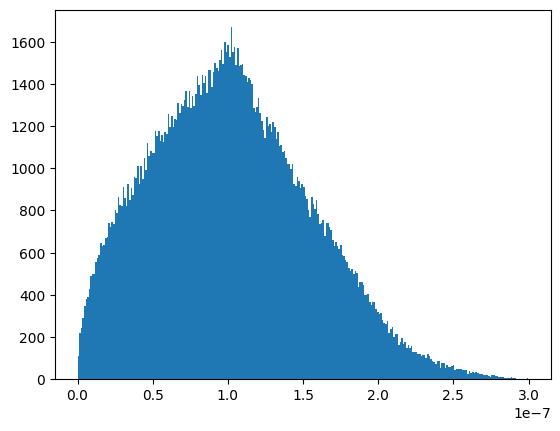

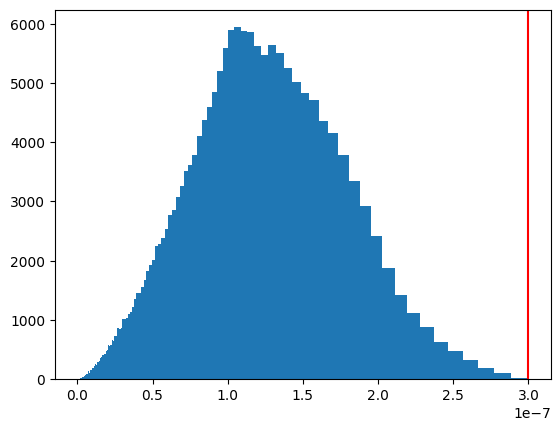

In [12]:
import matplotlib.pyplot as plt


def graficar_histograma(i, paso, movimiento, angulo, vel):
    """ 
    graficar_histograma (v 1.0) es una funcion que loa que hace es tomar la magnitud de todas las particulas del solido
    y plotearlas en un histograma con escala logaritmica y mostrar la velocidad máxima con una linea roja vertical
    Args: 
        i (int) : Es el paso de tiempo de la simulacion que se le hará el histograma
    Troubles:
        La escala lineal no permite nostrar adecuadamente la escala. Esto esta parcheado en la versión 2
    """
    
    df = lecturaparquet(i, paso, movimiento, angulo, vel) 
    
    # Filtramos la cama
    df = df[df["type"] == 1]
    
    # Calculamos velocidad magnitud
    vx = df["vx"].to_numpy()
    vy = df["vy"].to_numpy()
    vz = df["vz"].to_numpy()
    v_mag = ne.evaluate("vx**2 + vy**2 + vz**2")
    
    um = 0.01
    v_mag = v_mag[v_mag<um]
    hist,bins,_=plt.hist(v_mag,bins=280)
    plt.show()
    logbins = np.logspace(np.log10(bins[0]),np.log10(bins[-1]),len(bins))
    plt.hist(v_mag,bins=logbins)
    plt.axvline(max(v_mag),color='r')
    plt.show()
# Usalo con el último archivo de una simulación
paso, movimiento, angulo, vel = 50000 , [0 , 0 , 0] , 0 , -10
graficar_histograma(2, paso, movimiento, angulo, vel)

## ver. 1

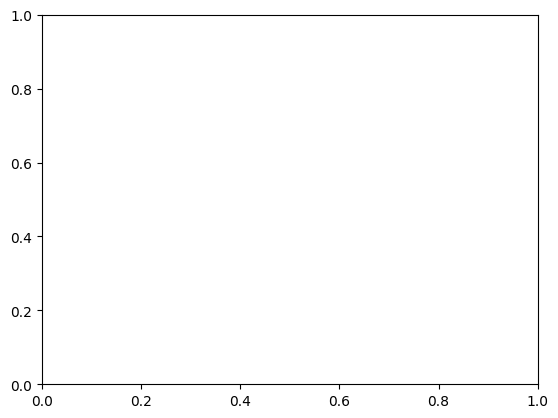

CalledProcessError: Command '['ffmpeg', '-f', 'rawvideo', '-vcodec', 'rawvideo', '-s', '640x480', '-pix_fmt', 'rgba', '-framerate', '2', '-loglevel', 'error', '-i', 'pipe:', '-filter_complex', 'split [a][b];[a] palettegen [p];[b][p] paletteuse', '-y', 'histograma_anim.gif']' returned non-zero exit status 255.

In [13]:
from matplotlib.animation import FuncAnimation
import matplotlib.pyplot as plt
import numpy as np
import numexpr as ne

def graficar_histograma(i, paso, movimiento, angulo, vel):
    """ 
    graficar_histograma (v 2.0) es una funcion que lo que hace es tomar la magnitud de todas las particulas del solido
    y plotearlas en un histograma con escala logaritmica y mostrar la velocidad máxima con una linea roja vertical.
    UPDATES:
    - Ahora la escala del eje x es logaritmica
    - Es una funcion que se utiliza para generar una animación
    Args: 
        i (int) : Es el paso de tiempo de la simulacion que se le hará el histograma
        paso (int) : Es la cantidad de steps entre imagenes descargadas de la simulación
        movimiento (list) : Es una lista con las coordenadas iniciales del proyectil 
        angulo (float) : Es el ángulo de rotación del proyectil en t = 0
        vel (float) : Es la velocidad inicial en el eje z del proyectil
    """
    ax.cla()  # Limpia el eje en cada frame
    
    df = lecturaparquet(i, paso, movimiento, angulo, vel)
    df = df[df["type"] == 1]

    vx = df["vx"].to_numpy()
    vy = df["vy"].to_numpy()
    vz = df["vz"].to_numpy()
    x = df["x"].to_numpy()
    y = df["y"].to_numpy()
    v_mag = ne.evaluate("vx**2 + vy**2 + vz**2")

    um = 0.005
    # 2. Pinta SOLO las de la meseta en Rojo (sobrepuesto)
    v_mag = v_mag[v_mag < um]
    # Bins normales
    hist, bins = np.histogram(v_mag, bins=280)
    # Log-bins
    logbins = np.logspace(np.log10(bins[0]), np.log10(bins[-1]), len(bins))

    ax.hist(v_mag, bins=logbins)
    ax.axvline(np.max(v_mag), color='r')
    ax.set_xscale("log",base=10)
    ax.set_title(f"Frame {i}")
    ax.set_xlabel(r"$v^2$")
    ax.set_xlim((10e-12,10e-3))
    ax.set_ylabel("Frecuencia (log)")

# -------------------------------
# Crear figura y animación
# -------------------------------

fig, ax = plt.subplots()

# Elegí cuántos frames querés animar: por ejemplo los primeros 50 archivos
frames_totales = 26
paso, movimiento, angulo, vel = 50000 , [0 , 0 , 0] , 0 , -10
anim = FuncAnimation(fig, lambda x : graficar_histograma(x, paso, movimiento, angulo, vel), frames=frames_totales, interval=1)

plt.show()
anim.save('histograma_anim.gif', fps=2)

## ver 2

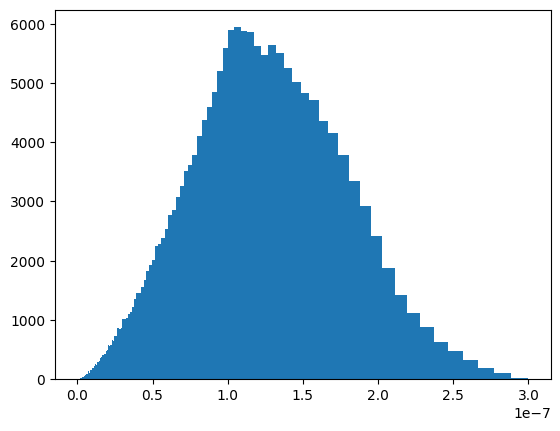

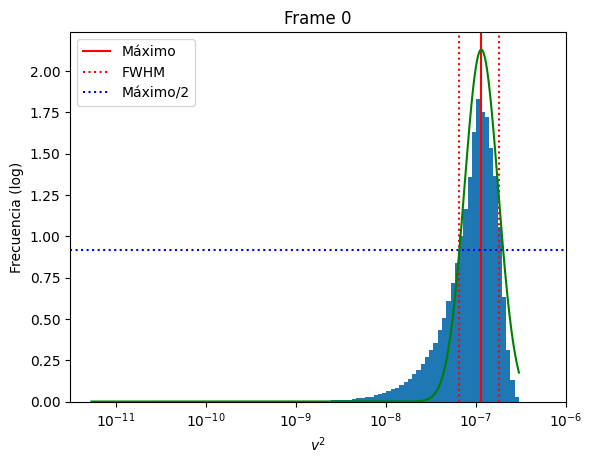

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import numexpr as ne
# Source - https://stackoverflow.com/a
# Posted by FizxMike, modified by community. See post 'Timeline' for change history
# Retrieved 2025-12-04, License - CC BY-SA 4.0
def FWHM(X,Y,p = 2.):
    """FWHM es una función que permite detectar el Full Width at Half Maximum (FWHM) de una distribución
    Args:
        X (list) : Es una lista que contiene la posición de los bins 
        Y (list) : Es la distribucion de los datos
        p (float) : Es un valor para ajustar el ancho de intervalo
    Returns:
        (list) : Devuelve el Full Width en forma de dos coordenadas"""
    half_max = max(Y) / p
    #find when function crosses line half_max (when sign of diff flips)
    #take the 'derivative' of signum(half_max - Y[])
    Xprima = (X[1:]-X[:-1])/2
    d = (-np.sign(half_max - np.array(Y[:-2])) + np.sign(half_max - np.array(Y[2:])))
    #plot(X[0:len(d)],d) #if you are interested
    #find the left and right most indexes
    left_idx = np.where(d > 0)[0][0]+1 ## Al tener los bines una coordenada mas que los datos se corre todo a la izquierda, para compensarlo sumamos 1
    right_idx = np.where(d < 0)[-1][-1]+1
    return X[left_idx],X[right_idx]  #return the difference (full width)
F = lambda x,mu,sigma : (sigma * np.sqrt(2*np.pi) * np.exp((x - mu)**2 / (2 * sigma**2 ) ))**-1

i=0
df = lecturaparquet(i, 50000, [0,0,0],0,-10)
df = df[df["type"] == 1]

vx = df["vx"].to_numpy()
vy = df["vy"].to_numpy()
vz = df["vz"].to_numpy()
x = df["x"].to_numpy()
y = df["y"].to_numpy()
v2 = ne.evaluate("vx**2 + vy**2 + vz**2")
log_datos = np.log10(v2)
data = v2[(v2<0.005)] 
_, bins = np.histogram(v2, bins=280)

# Log-bins
logbins = np.logspace(np.log10(bins[0]), np.log10(bins[-1]), len(bins))

histograma = plt.hist(v2, bins=logbins)
valor_central = np.mean(FWHM(histograma[1],histograma[0],p=1.0965)) ## Al estar usando un metodo de derivada primera, si ponemos 1 se va a ir a las colas que la derivada converge a 0 más rapido que en el máximo
Full_Width = FWHM(histograma[1],histograma[0])

fig, ax = plt.subplots()
histograma2 = ax.hist(log_datos, bins=100,density=True)
ax.axvline(np.log10(valor_central), color='r',label="Máximo")
ax.axvline(np.log10(Full_Width[0]), color='r',linestyle=":",label="FWHM")
ax.axvline(np.log10(Full_Width[1]),color="r",linestyle=":")
ax.axhline(max(histograma2[0])/2,color="b",linestyle=":",label="Máximo/2")

X = np.linspace(min(log_datos),max(log_datos),1000)

plt.plot(X,F(X,np.log10(valor_central),abs(np.log10(Full_Width[1]/Full_Width[0]))/(2*np.sqrt(np.log(4)))),"g")

labels_locs = np.arange(int(min(log_datos)), int(max(log_datos)) + 1)
ax.set_xticks(labels_locs)
ax.set_xticklabels([f"$10^{{{i}}}$" for i in labels_locs])
ax.set_yscale("linear")
ax.set_title(f"Frame {i}")
ax.set_xlabel(r"$v^2$")
ax.set_ylabel("Frecuencia (log)")
ax.legend()
plt.show()



## ver 3 (final)

Media (potencia de 10): -6.998156065315966 -> equivale a 10^-6.998156065315966
Ancho (sigma en decadas): -0.18832641128090716


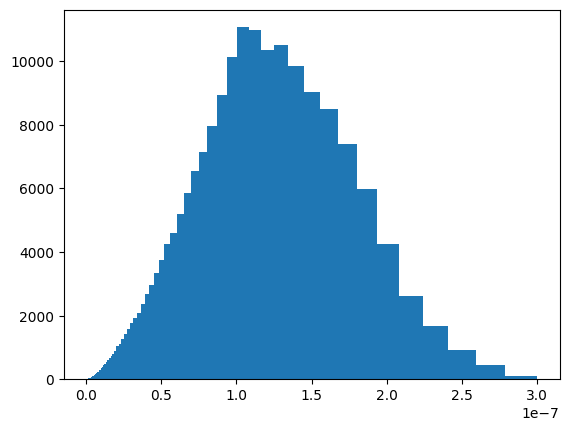

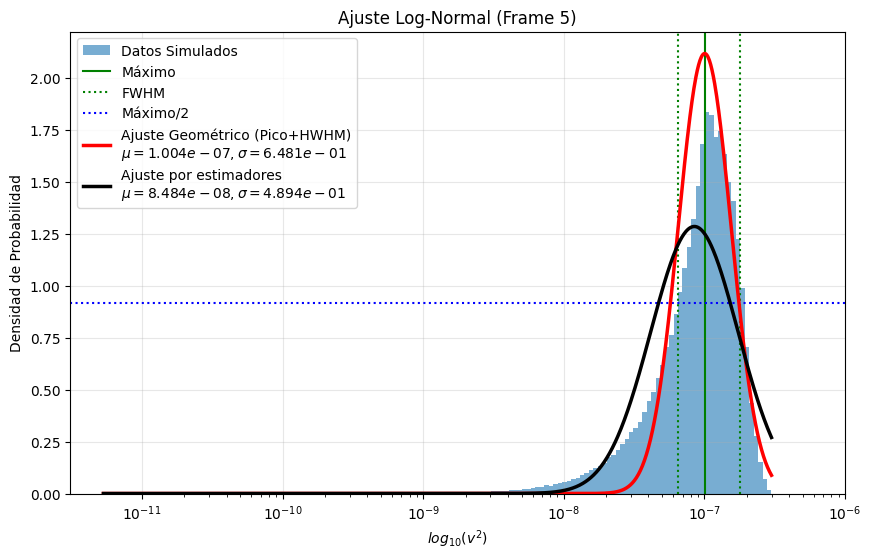

--- RESULTADOS DEL TEST DE ENERGÍA ---
1. Energía Media REAL (Simulación): 1.023884e-07 (Referencia)

2. Ajuste ESTIMADORES (Curva Negra/Desplazada):
   - Predicción: 1.095189e-07
   - Error: 6.96%

3. Ajuste GEOMÉTRICO (Curva Roja/Bonita):
   - Predicción: 1.103257e-07
   - Error: 7.75%


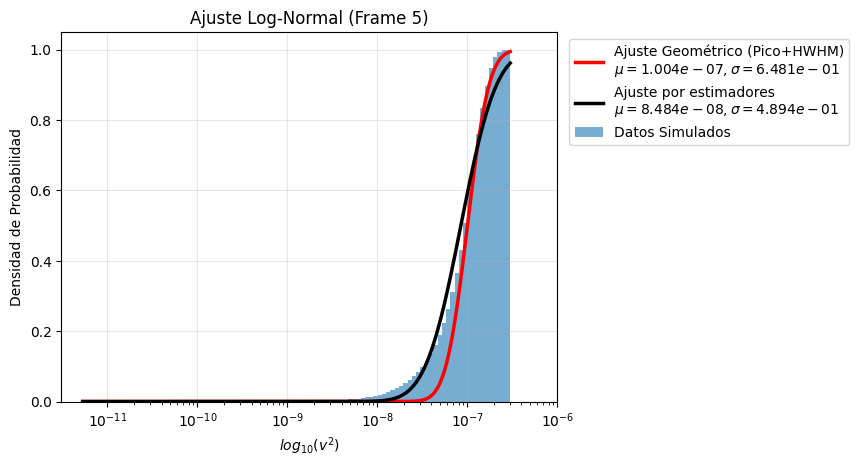

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

import numexpr as ne
def FWHM(X,Y,p = 2.):
    """FWHM es una función que permite detectar el Full Width at Half Maximum (FWHM) de una distribución
    Args:
        X (list) : Es una lista que contiene la posición de los bins 
        Y (list) : Es la distribucion de los datos
        p (float) : Es un valor para ajustar el ancho de intervalo
    Returns:
        (list) : Devuelve el Full Width en forma de dos coordenadas"""
    half_max = max(Y) / p
    #find when function crosses line half_max (when sign of diff flips)
    #take the 'derivative' of signum(half_max - Y[])
    Xprima = (X[1:]-X[:-1])/2
    d = (-np.sign(half_max - np.array(Y[:-2])) + np.sign(half_max - np.array(Y[2:])))
    #plot(X[0:len(d)],d) #if you are interested
    #find the left and right most indexes
    left_idx = np.where(d > 0)[0][0]+1 ## Al tener los bines una coordenada mas que los datos se corre todo a la izquierda, para compensarlo sumamos 1
    right_idx = np.where(d < 0)[-1][-1]+1
    return X[left_idx],X[right_idx]  #return the difference (full width)
    
# 1. TRUCO: Transforma tus datos al espacio logarítmico
# Filtramos ceros o negativos para evitar errores

j = 5
df = lecturaparquet(j, 50000, [0,0,0],0,-10)
df = df[df["type"] == 1]

vx , vy , vz = df["vx"].to_numpy() , df["vy"].to_numpy() ,  df["vz"].to_numpy()
v2 = ne.evaluate("vx**2 + vy**2 + vz**2")
v2 = v2[v2<0.005] 

log_data = np.log10(v2)


_, bins = np.histogram(v2, bins=150)
# Log-bins
logbins = np.logspace(np.log10(bins[0]), np.log10(bins[-1]), len(bins))

fig, ax = plt.subplots()
histograma = ax.hist(v2, bins=logbins)

valor_central = histograma[1][np.where(histograma[0]==max(histograma[0]))][0]
Full_Width = FWHM(histograma[1],histograma[0])


# 2. Ajuste automático (Mejor que hacerlo a ojo con FWHM)
# scipy encuentra el mu y sigma óptimos por ti
mu_log, sigma_log = np.log10(valor_central),np.log10(Full_Width[1]/Full_Width[0])/(2*np.sqrt(np.log(4)))

print(f"Media (potencia de 10): {mu_log} -> equivale a 10^{mu_log}")
print(f"Ancho (sigma en decadas): {sigma_log}")

# 3. Ploteo
plt.figure(figsize=(10, 6))

# Histograma de los LOGARITMOS (usando bins lineales ahora)
# Al ser bins lineales en espacio log, density=True funciona perfecto.
histograma2 = plt.hist(log_data, bins=150, density=True, alpha=0.6, label='Datos Simulados')

# Generar la curva de ajuste
x_axis = np.linspace(min(log_data), max(log_data), 1000)
pdf_ajuste = norm.pdf(x_axis, mu_log, sigma_log)


plt.axvline(np.log10(valor_central), color='g',label="Máximo")
plt.axvline(np.log10(Full_Width[0]), color='g',linestyle=":",label="FWHM")
plt.axvline(np.log10(Full_Width[1]), color="g",linestyle=":")
plt.axhline(max(histograma2[0])/2  , color="b",linestyle=":",label="Máximo/2")


# Curva forzada geométricamente
x_axis = np.linspace(min(log_data), max(log_data), 1000)
mu_est, sigma_est = np.mean(log_data),np.std(log_data)
# --- 2. CANDIDATO A: AJUSTE POR ESTIMADORES (CURVA NEGRA) ---
# Calcula mu y sigma matemáticamente (MLE)

plt.plot(x_axis, norm.pdf(x_axis,mu_log,abs(sigma_log)), 'r-', linewidth=2.5, label=f'Ajuste Geométrico (Pico+HWHM)\n$\mu={10**mu_log:.3e}, \sigma={10**sigma_log:.3e}$')
plt.plot(x_axis, norm.pdf(x_axis,mu_est,sigma_est), 'k-', linewidth=2.5, label=f'Ajuste por estimadores \n$\mu={10**mu_est:.3e}, \sigma={10**-sigma_est:.3e}$')


# Maquillaje de ejes
longitud_d = 1 ## Es la cantidad de espacio a la derecha que se deja en el gráfico
longitud_i = 0 ## Es la cantidad de espacio a la izquierda que se deja en el gráfico
delta_longitud = abs(longitud_d-longitud_i)
ticks_locs = np.arange(round(min(log_data)) - longitud_i, np.ceil(max(log_data)) + longitud_d,dtype=float)

cant = len(ticks_locs)
minor_ticks = np.zeros((cant-1)*9+1)
for i in range(cant-1):
    minor_ticks[i*9:i*9+9]= np.log10(np.linspace(10**ticks_locs[i],10**ticks_locs[i+1],10))[:-1]
    
minor_ticks[-1] = ticks_locs[-1]

plt.xticks(ticks_locs, [f"$10^{{{int(i)}}}$" for i in ticks_locs])
plt.xticks(ticks=minor_ticks, labels=["" for i in minor_ticks],minor=True)
plt.xlabel(r"$log_{10}(v^2)$")
plt.ylabel("Densidad de Probabilidad")
plt.title(f"Ajuste Log-Normal (Frame {j})")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# --- 1. DATOS REALES (LA VERDAD) --- (ESTO ESTA FUNCIONADO MAL FABRI DEL FUTURO ARREGALOS)
# Filtramos igual que antes


# Energía Media Real (El promedio simple de tus datos)
energia_real = np.mean(v2)

print(f"--- RESULTADOS DEL TEST DE ENERGÍA ---")
print(f"1. Energía Media REAL (Simulación): {energia_real:.6e} (Referencia)\n")



# Conversión de base 10 a base natural (e) para la fórmula física
# Porque la fórmula E[X] = exp(mu + sigma^2/2) usa logaritmo natural
mu_ln_est = mu_est * np.log(10)
sigma_ln_est = sigma_est * np.log(10)

# Energía Teórica (Esperanza Matemática)
energia_est = np.exp(mu_ln_est + (sigma_ln_est**2) / 2)
error_est = abs(energia_est - energia_real) / energia_real * 100

print(f"2. Ajuste ESTIMADORES (Curva Negra/Desplazada):")
print(f"   - Predicción: {energia_est:.6e}")
print(f"   - Error: {error_est:.2f}%")


# Conversión a base natural

mu_ln_geo = mu_log * np.log(10)
sigma_ln_geo = sigma_log * np.log(10)

# Energía Teórica
energia_geo = np.exp(mu_ln_geo + (sigma_ln_geo**2) / 2)
error_geo = abs(energia_geo - energia_real) / energia_real * 100

print(f"\n3. Ajuste GEOMÉTRICO (Curva Roja/Bonita):")
print(f"   - Predicción: {energia_geo:.6e}")
print(f"   - Error: {error_geo:.2f}%")
plt.plot(x_axis, norm.cdf(x_axis,mu_log,abs(sigma_log)), 'r-', linewidth=2.5, label=f'Ajuste Geométrico (Pico+HWHM)\n$\mu={10**mu_log:.3e}, \sigma={10**sigma_log:.3e}$')
plt.plot(x_axis, norm.cdf(x_axis,mu_est,sigma_est), 'k-', linewidth=2.5, label=f'Ajuste por estimadores \n$\mu={10**mu_est:.3e}, \sigma={10**-sigma_est:.3e}$')
plt.hist(log_data, bins=100, density=True, alpha=0.6, label='Datos Simulados',cumulative=True)

    
plt.xticks(ticks_locs, [f"$10^{{{int(i)}}}$" for i in ticks_locs])
plt.xticks(ticks=minor_ticks, labels=["" for i in minor_ticks],minor=True)
plt.xlabel(r"$log_{10}(v^2)$")
plt.ylabel("Densidad de Probabilidad")
plt.title(f"Ajuste Log-Normal (Frame {j})")
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(True, alpha=0.3)

plt.show()

# Lorentz plot

## ver. 0

NameError: name 'update_plot' is not defined

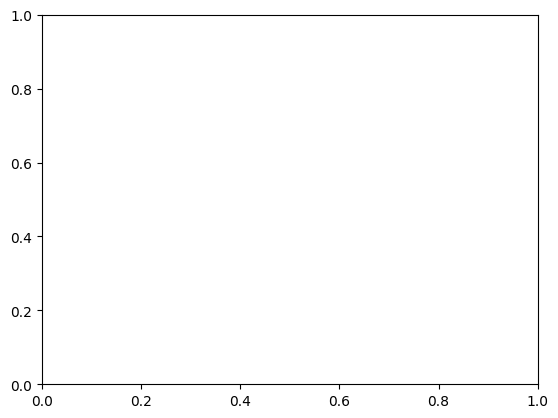

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
def update_lorentz(i):
    ax.cla()  # Limpia el eje en cada frame
    
    df = lecturaparquet(i, paso, movimiento, angulo, vel)
    df = df[df["type"] == 1]

    vx = df["vx"].to_numpy()
    vy = df["vy"].to_numpy()
    vz = df["vz"].to_numpy()
    v2 = ne.evaluate("vx**2 + vy**2 + vz**2")
    # --- 1. PREPARACIÓN DE DATOS ---
    # Usamos tus datos limpios
    
    
    v2_clean = v2[(v2 > 0) & (v2 < 0.005)]
    
    # Para la curva de Lorenz, necesitamos los datos ORDENADOS de menor a mayor
    energy_sorted = np.sort(v2_clean)
    
    # --- 2. CÁLCULO DE LA CURVA DE LORENZ ---
    # Eje X: Fracción acumulada de partículas (del 0 al 1)
    n = len(energy_sorted)
    cum_people = np.arange(1, n + 1) / n
    
    # Eje Y: Fracción acumulada de energía
    # cumsum() va sumando la energía paso a paso
    cum_energy = np.cumsum(energy_sorted)
    # Normalizamos dividiendo por la energía total para que vaya de 0 a 1
    cum_energy = cum_energy / cum_energy[-1]
    
    # --- 3. CÁLCULO DEL COEFICIENTE DE GINI ---
    # El Gini es básicamente el área entre la diagonal perfecta y tu curva
    # Fórmula rápida usando la integral trapezoidal
    area_bajo_curva = np.trapz(cum_energy, cum_people)
    gini = 1 - 2 * area_bajo_curva
    
    # --- 4. ENCONTRAR EL PUNTO DE QUIEBRE (PARETO) ---
    # ¿Qué porcentaje de partículas tiene el 80% de la energía?
    # Buscamos dónde la curva cruza el 0.2 (porque 1 - 0.8 = 0.2 de riqueza acumulada desde abajo)
    # O más fácil: ¿Cuánto tiene el Top 10%?
    idx_90 = int(n * 0.90)
    energia_del_top_10 = 1 - cum_energy[idx_90]
  
 
    # La Curva de tus datos
    ax.plot(cum_people, cum_energy, 'r-', linewidth=3, label=f'Tu Sistema (Gini={gini:.4f})')
    
    # La Línea de Igualdad Perfecta (Referencia)
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Equilibrio Perfecto (Equipartición)')
    
    # Decoración
    ax.set_title(f"Curva de Lorenz: Distribución de la Energía Cinética, frame {i}")
    ax.set_xlabel("Fracción Acumulada de Partículas (Ordenadas por $v^2$)")
    ax.set_ylabel("Fracción Acumulada de Energía Total")
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Anotación visual del Top 10%
    ax.axvline(0.9, color='blue', linestyle=':', alpha=0.6)
    ax.plot(0.9, cum_energy[idx_90], 'bo')
    ax.text(0.5, 0.6, f"El 90% más lento\nsolo tiene el {(cum_energy[idx_90]*100):.2f}% de la energía", 
             fontsize=10, color='blue')

# -------------------------------
# Crear figura y animación
# -------------------------------

fig, ax = plt.subplots()

# Elegí cuántos frames querés animar: por ejemplo los primeros 50 archivos
frames_totales = 26

anim = FuncAnimation(fig, update_lorentz, frames=frames_totales, interval=1)

plt.show()
anim.save('histograma_anim_lorentz_plot.gif', fps=2)


## ver. 1

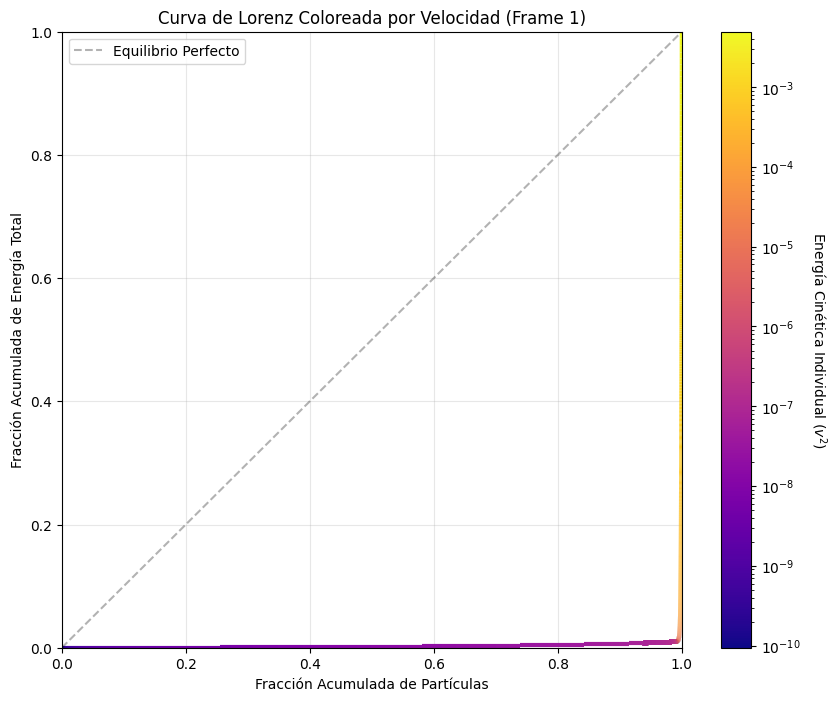

In [145]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LogNorm
from data_extractor import lecturaparquet
# --- 1. PREPARAR DATOS ---
# Usamos tus datos limpios (v2)
i=1
df = lecturaparquet(i, 50000,[0,0,0],0,-10)
df = df[df["type"] == 1]

vx = df["vx"].to_numpy()
vy = df["vy"].to_numpy()
vz = df["vz"].to_numpy()
v2 = ne.evaluate("vx**2 + vy**2 + vz**2")
v2_clean = v2[(v2 > 0) & (v2 < 0.005)]
energy_sorted = np.sort(v2_clean)

# Coordenadas Lorenz (Igual que antes)
n = len(energy_sorted)
cum_people = np.arange(1, n + 1) / n
cum_energy = np.cumsum(energy_sorted)
cum_energy = cum_energy / cum_energy[-1]

# --- 2. TRUCO VISUAL: LINEA MULTICOLOR ---
# Para cambiar el color de una línea tramo a tramo, necesitamos "LineCollection"
# Creamos segmentos: [(x0, y0), (x1, y1)], [(x1, y1), (x2, y2)], ...
points = np.array([cum_people, cum_energy]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# --- 3. PLOTEO ---
fig, ax = plt.subplots(figsize=(10, 8))
v_max_visual = np.percentile(energy_sorted, 100)
v_min_visual = np.percentile(energy_sorted, 0.1)
# Normalización Logarítmica para el color (porque tus velocidades varían en órdenes de magnitud)
norm = LogNorm(vmin=v_min_visual, vmax=v_max_visual)

# Creamos la colección de líneas coloreadas por v^2, plasma inferno
lc = LineCollection(segments, cmap='plasma', norm=norm,alpha=1)
lc.set_array(energy_sorted) # Usamos v^2 para decidir el color
lc.set_linewidth(3)
line = ax.add_collection(lc)

# Referencia (Diagonal)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Equilibrio Perfecto')

# Barra de Color (La clave para leer el gráfico)
cbar = fig.colorbar(line, ax=ax)
cbar.set_label(r'Energía Cinética Individual ($v^2$)', rotation=270, labelpad=20)

# Ajustes finales
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title(f"Curva de Lorenz Coloreada por Velocidad (Frame {i})")
ax.set_xlabel("Fracción Acumulada de Partículas")
ax.set_ylabel("Fracción Acumulada de Energía Total")
ax.grid(True, alpha=0.3)
ax.legend(loc='upper left')

# --- 4. CÓMO VER UN RANGO (VISUALMENTE) ---
# Ejemplo: Queremos ver dónde están las partículas entre 10^-8 y 10^-6
# Dibujamos líneas horizontales en la barra de color o regiones sombreadas
# (Esto es opcional, el color ya te lo dice)

plt.show()

## ver. 2

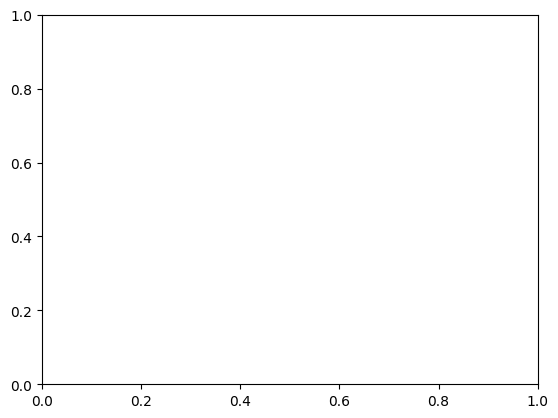

In [146]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LogNorm
from matplotlib.collections import LineCollection
from data_extractor import lecturaparquet
def update_lorentz(i, paso, movimiento, angulo, vel):
    global j
    j+=1
    ax.cla()

    df = lecturaparquet(i, paso, movimiento, angulo, vel)
    df = df[df["type"] == 1]

    vx = df["vx"].to_numpy()
    vy = df["vy"].to_numpy()
    vz = df["vz"].to_numpy()
    v2 = ne.evaluate("vx**2 + vy**2 + vz**2")
    # --- 1. PREPARACIÓN DE DATOS ---
    # Usamos tus datos limpios
    
    
    v2_clean = v2[(v2 > 0) & (v2 < 0.005)]
    
    # Para la curva de Lorenz, necesitamos los datos ORDENADOS de menor a mayor
    energy_sorted = np.sort(v2_clean)
    
    # --- 2. CÁLCULO DE LA CURVA DE LORENZ ---
    # Eje X: Fracción acumulada de partículas (del 0 al 1)
    n = len(energy_sorted)
    cum_people = np.arange(1, n + 1) / n
    
    # Eje Y: Fracción acumulada de energía
    # cumsum() va sumando la energía paso a paso
    cum_energy = np.cumsum(energy_sorted)
    # Normalizamos dividiendo por la energía total para que vaya de 0 a 1
    cum_energy = cum_energy / cum_energy[-1]
    
    # --- 3. CÁLCULO DEL COEFICIENTE DE GINI ---
    # El Gini es básicamente el área entre la diagonal perfecta y tu curva
    # Fórmula rápida usando la integral trapezoidal
    area_bajo_curva = np.trapz(cum_energy, cum_people)
    gini = 1 - 2 * area_bajo_curva
    
    # --- 4. ENCONTRAR EL PUNTO DE QUIEBRE (PARETO) ---
    # ¿Qué porcentaje de partículas tiene el 80% de la energía?
    # Buscamos dónde la curva cruza el 0.2 (porque 1 - 0.8 = 0.2 de riqueza acumulada desde abajo)
    # O más fácil: ¿Cuánto tiene el Top 10%?
    idx_90 = int(n * 0.90)
    energia_del_top_10 = 1 - cum_energy[idx_90]
    # --- 2. TRUCO VISUAL: LINEA MULTICOLOR ---
    # Para cambiar el color de una línea tramo a tramo, necesitamos "LineCollection"
    # Creamos segmentos: [(x0, y0), (x1, y1)], [(x1, y1), (x2, y2)], ...
    points = np.array([cum_people, cum_energy]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    
    # Normalización Logarítmica para el color (porque tus velocidades varían en órdenes de magnitud)
    #v_max_visual = np.max(energy_sorted)
    #v_min_visual = np.min(energy_sorted)
    norm = LogNorm(vmin=5e-10, vmax=1e-5)
    
    # Creamos la colección de líneas coloreadas por v^2, plasma inferno
    lc = LineCollection(segments, cmap='plasma', norm=norm,alpha=1)
    lc.set_array(energy_sorted) # Usamos v^2 para decidir el color
    lc.set_linewidth(3)
    line = ax.add_collection(lc)
       
    # Barra de Color (La clave para leer el gráfico)
    if i==0 and j==1:
        global cbar 
        cbar = fig.colorbar(line, ax=ax)
        cbar.set_label(r'Energía Cinética Individual ($v^2$)', rotation=270, labelpad=20)
    else:
        cbar.update_normal(line)


    # La Línea de Igualdad Perfecta (Referencia)
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Equilibrio Perfecto (Equipartición)')
    
    # Decoración
    ax.set_title(f"Curva de Lorenz: Distribución de la Energía Cinética, frame {i}")
    ax.set_xlabel("Fracción Acumulada de Partículas (Ordenadas por $v^2$)")
    ax.set_ylabel("Fracción Acumulada de Energía Total")
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Anotación visual del Top 10%
    ax.axvline(0.9, color='blue', linestyle=':', alpha=0.6)
    ax.plot(0.9, cum_energy[idx_90], 'bo')
    ax.text(0.2, 0.6, f"El 90% más lento\nsolo tiene el {(cum_energy[idx_90]*100):.2f}% \nde la energía", 
             fontsize=10, color='blue')
    
# -------------------------------
# Crear figura y animación
# -------------------------------
j=0
fig, ax = plt.subplots()

# Elegí cuántos frames querés animar: por ejemplo los primeros 50 archivos
frames_totales = 26

anim = FuncAnimation(fig, lambda x : update_lorentz(x, paso = 50000, movimiento = [0 , 0 , 0], angulo = 0, vel = -10), frames=frames_totales, interval=1)

plt.show()
anim.save('histograma_anim_lorentz_plot.gif', fps=2)
